# Structural fault dictionaries of the Ladenheim networks

This notebook loads the catalogue of the 99 series–parallel networks of Ladenheim's catalogue, draws the schematic of a chosen network and computes its structural fault dictionary with `MExpr`. Everything is obtained from the m-expression of the network alone: no element values and no simulation.

Elements: resistor $R$ (m-letter $B$), inductor $L$ (m-letter $C$), capacitor $C$ (m-letter $A$). Operators: `s` series, `p` parallel.

In [ ]:
%pip install -r requirements.txt

## The catalogue

Each row gives the network number from the catalogue, its realisation with circuit elements and the same network as an m-expression.

In [2]:
import pandas as pd
from IPython.display import Markdown, display

from mexpr import MExpr
from schematic import draw

In [3]:
nets = pd.read_csv('data/ladenheim_networks.csv', encoding='utf-8-sig')
nets.columns = ['network', 'realisation', 'mexpr']
nets['elements'] = nets.realisation.str.count('[RLC]')
nets['reactive'] = nets.realisation.str.count('[LC]')

print(f'{len(nets)} networks')
nets.head(10)

99 networks


,network,realisation,mexpr,elements,reactive
0,1,L,C,1,1
1,2,C,A,1,1
2,3,R,B,1,0
3,4,L s C,C s A,2,2
4,5,R s C,B s A,2,1
5,6,R s L,B s C,2,1
6,7,L p C,C p A,2,2
7,8,R p L,B p C,2,1
8,9,R p C,B p A,2,1
9,10,R s L s C,B s C s A,3,2


The numbering follows the catalogue, so it has gaps: the nine bridge networks are not series–parallel and are not in the list. Number of networks by number of elements:

In [4]:
nets.groupby('elements').size().rename('networks').to_frame().T

elements,1,2,3,4,5
networks,3,6,16,34,40


## The schematic of one network

Change `number` to any network of the catalogue. The grey labels under the elements are the labels used in the fault tables below.

realisation : R s (L p (R s C))
m-expression: B1 s (C1 p (B2 s A1))


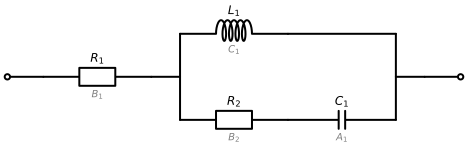

In [5]:
number = 63

row = nets.set_index('network').loc[number]
e = MExpr(row.mexpr)
print('realisation :', row.realisation)
print('m-expression:', e)
draw(e)

## Its structural fault dictionary

The m-word of the network, its canonical form and the signature $\Phi = (v(l), \lambda_s, \lambda_p, v(r))$:

In [6]:
print('m-word     :', e.mword.l2U, '->', e.word)
print('signature  :', e.quadruple)
print('corners    :', e.corners())

m-word     : BBcbCCacABbAaBBB -> BCAB
signature  : (0, 2, 2, 0)
corners    : {'delta_0': 'B1', 'delta_inf': 'B1 s B2', 'delta_K': 'B1', 'delta_P': 'P'}


Every element shorted (`K`) and opened (`P`): the residual network, its m-word and signature, and the test that detects the fault. A fault marked `undetectable` is *structurally undetectable*: its signature equals the nominal one, so none of the three signature tests (DC, HF, corner count) detects it for any element values. Such a fault may still be detectable through value-dependent features of the response, such as a change of level or of damping.

In [7]:
faults = pd.DataFrame(e.faults())
faults

,element,kind,residual,word,quadruple,test,undetectable
0,B1,K,C1 p (B2 s A1),CAB,"(1, 2, 1, 0)",DC+sweep,False
1,B1,P,P,P,None,port,False
2,C1,K,B1,B,"(0, 0, 0, 0)",sweep,False
3,C1,P,B1 s B2 s A1,AB,"(-1, 0, 1, 0)",DC+sweep,False
4,B2,K,B1 s (C1 p A1),BCAB,"(0, 2, 2, 0)",none,True
5,B2,P,B1 s C1,BC,"(0, 0, 1, 1)",HF+sweep,False
6,A1,K,B1 s (C1 p B2),BCB,"(0, 1, 1, 0)",sweep,False
7,A1,P,B1 s C1,BC,"(0, 0, 1, 1)",HF+sweep,False


A residual network can be drawn like any other. Here the fault `B2 K`, a shorted $R_2$:

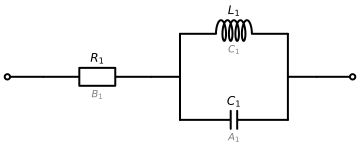

In [8]:
draw(e.substitute({'B2': 'K'}.get))

Groups of faults that a port measurement cannot tell apart, as in the paper. *Structural* groups have the same residual network after merging of same-type neighbours (same topology and element types, possibly different values). *Absolute* groups are the sub-groups of a structural group formed by all opens of one series node or all shorts of one parallel node; their residual networks are identical, element values included. *Signature* groups share the quadruple.

In [9]:
e.ambiguity_groups()

{'structural': [['B2 P', 'A1 P']],
 'absolute': [['B2 P', 'A1 P']],
 'signature': [['nominal', 'B2 K'], ['B2 P', 'A1 P']]}

## Your own network

Any series–parallel m-expression works, also one that is not in the catalogue. Mixed `s` and `p` on one level need parentheses.

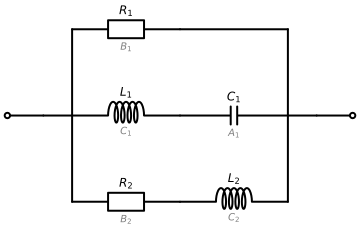

,element,kind,residual,word,quadruple,test,undetectable
0,B1,K,K,K,None,port,False
1,B1,P,(C1 s A1) p (B2 s C2),BACBC,"(0, 2, 3, 1)",HF+sweep,False
2,C1,K,B1 p A1 p (B2 s C2),BCA,"(0, 2, 1, -1)",HF+sweep,False
3,C1,P,B1 p (B2 s C2),BCB,"(0, 1, 1, 0)",sweep,False
4,A1,K,B1 p C1 p (B2 s C2),CBCB,"(1, 2, 1, 0)",DC+sweep,False
5,A1,P,B1 p (B2 s C2),BCB,"(0, 1, 1, 0)",sweep,False
6,B2,K,B1 p (C1 s A1) p C2,CACB,"(1, 3, 2, 0)",DC+sweep,False
7,B2,P,B1 p (C1 s A1),BACB,"(0, 2, 2, 0)",sweep,False
8,C2,K,B1 p (C1 s A1) p B2,BACB,"(0, 2, 2, 0)",sweep,False
9,C2,P,B1 p (C1 s A1),BACB,"(0, 2, 2, 0)",sweep,False


In [10]:
mine = MExpr('B p (C s A) p (B s C)')
display(draw(mine))
pd.DataFrame(mine.faults())